In [ ]:
# CSV_PATH = "../archive/old_data/northAtlanticOcean.csv"

In [1]:
import os
print(os.getcwd())
print(os.path.exists("../archive/old_data/northAtlanticOcean.csv"))

c:\Users\irego\Desktop\balinam\notebooks
True


=== A) Sorunlu satırlar (tarihi veya koordinatı bozuk) ===
           id eventDate  decimalLatitude  decimalLongitude
1413   423732       NaN              NaN               NaN
14764  338751       NaN              NaN               NaN
14849  436619       NaN              NaN               NaN
14927  409895       NaN              NaN               NaN
15035  410474       NaN              NaN               NaN
15280  424578       NaN              NaN               NaN

=== B) Yıllara göre kayıt sayısı ===
date
1972.0       1
1975.0       4
1976.0       9
1977.0      16
1978.0     193
1979.0     321
1980.0     194
1981.0      47
1982.0     287
1983.0     315
1984.0     134
1985.0     109
1986.0      58
1987.0      18
1988.0       7
1989.0      12
1990.0      51
1991.0      50
1992.0     508
1993.0     513
1994.0      54
1995.0      15
1996.0       2
1998.0       5
1999.0       3
2000.0      12
2001.0       4
2002.0       9
2003.0      59
2004.0     421
2005.0     840
2006.0      30
2007.

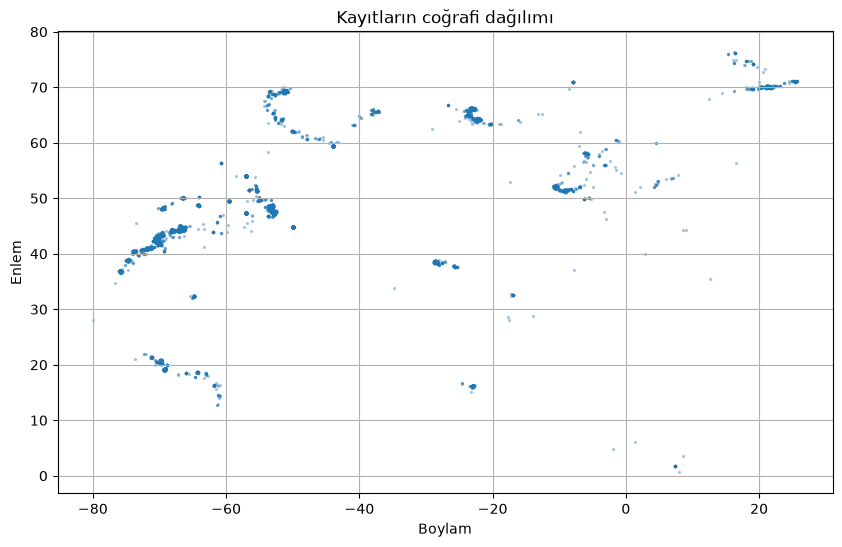

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "../archive/old_data/northAtlanticOcean.csv"
df = pd.read_csv(CSV_PATH, low_memory=False)

# Tarih ve birey kimliği
df["date"] = pd.to_datetime(df["eventDate"], format="ISO8601", errors="coerce").dt.normalize()
df["whale_id"] = df["organismID"].str.extract(r"individual/(\d+)")[0]

print("=== A) Sorunlu satırlar (tarihi veya koordinatı bozuk) ===")
bad = df[df["date"].isna() | df["decimalLatitude"].isna() | df["decimalLongitude"].isna()]
print(bad[["id", "eventDate", "decimalLatitude", "decimalLongitude"]].to_string())

print("\n=== B) Yıllara göre kayıt sayısı ===")
print(df["date"].dt.year.value_counts().sort_index().to_string())

print("\n=== C) Aylara göre kayıt sayısı ===")
print(df["date"].dt.month.value_counts().sort_index().to_string())

print("\n=== D) En çok kayıt olan günler ===")
print(df["date"].value_counts().head(10).to_string())

print("\n=== E) eventDate uzunlukları (yalnızca yıl/ay olan kayıt var mı?) ===")
print(df["eventDate"].astype(str).str.len().value_counts().to_string())

print("\n=== F) Koordinat belirsizliği (metre) ===")
print(df["coordinateUncertaintyInMeters"].describe().to_string())

# Harita
ok = df.dropna(subset=["decimalLatitude", "decimalLongitude"])
plt.figure(figsize=(10, 6))
plt.scatter(ok["decimalLongitude"], ok["decimalLatitude"], s=2, alpha=0.3)
plt.xlabel("Boylam")
plt.ylabel("Enlem")
plt.title("Kayıtların coğrafi dağılımı")
plt.grid(True)
plt.show()

Loaded: ..\archive\old_data\northAtlanticOcean.csv | shape: (15707, 27)
Unparseable dates: 6
Date range: 1972-06-28 -> 2024-10-30
Records with a whale ID: 13902 / 15707
Unique individuals: 6598

=== A) Unusable rows (missing date or coordinates) ===
           id eventDate  decimalLatitude  decimalLongitude
1413   423732       NaN              NaN               NaN
14764  338751       NaN              NaN               NaN
14849  436619       NaN              NaN               NaN
14927  409895       NaN              NaN               NaN
15035  410474       NaN              NaN               NaN
15280  424578       NaN              NaN               NaN

=== B) Records per year ===
obs_year
1972       1
1975       4
1976       9
1977      16
1978     193
1979     321
1980     194
1981      47
1982     287
1983     315
1984     134
1985     109
1986      58
1987      18
1988       7
1989      12
1990      51
1991      50
1992     508
1993     513
1994      54
1995      15
1996       2


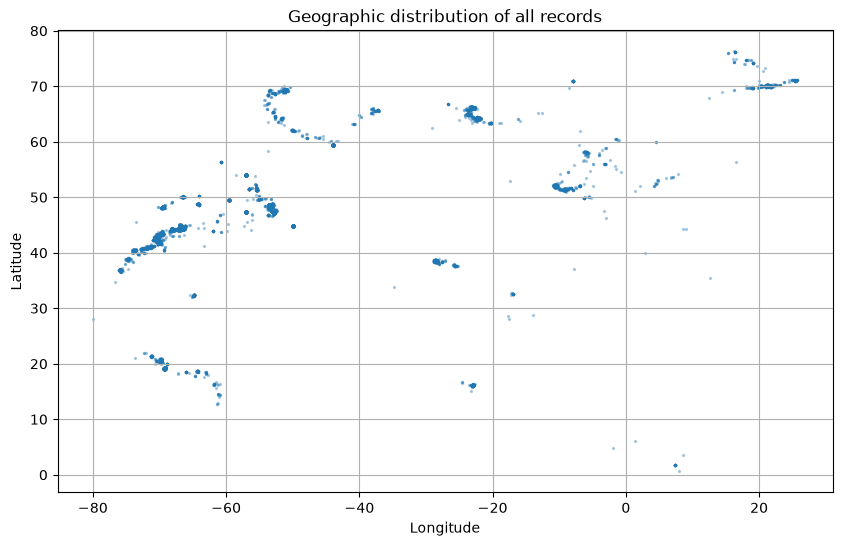

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Load the raw file (tries the usual locations) ---
CANDIDATE_PATHS = [
    Path("../archive/old_data/northAtlanticOcean.csv"),  # notebook inside notebooks/
    Path("archive/old_data/northAtlanticOcean.csv"),     # notebook in project root
    Path("northAtlanticOcean.csv"),                      # file next to the notebook
]
CSV_PATH = next((p for p in CANDIDATE_PATHS if p.exists()), None)
if CSV_PATH is None:
    raise FileNotFoundError("CSV not found. Current folder: " + str(Path.cwd()))

raw = pd.read_csv(CSV_PATH, low_memory=False)
print("Loaded:", CSV_PATH, "| shape:", raw.shape)

# --- Parse dates and whale IDs (work on a copy, never on raw) ---
df = raw.copy()
df["date"] = pd.to_datetime(df["eventDate"], format="ISO8601", errors="coerce").dt.normalize()
df["whale_id"] = df["organismID"].str.extract(r"individual/(\d+)")[0]
df["obs_year"] = df["date"].dt.year
df["obs_month"] = df["date"].dt.month
df["obs_day"] = df["date"].dt.day

print("Unparseable dates:", int(df["date"].isna().sum()))
print("Date range:", df["date"].min().date(), "->", df["date"].max().date())
print("Records with a whale ID:", int(df["whale_id"].notna().sum()), "/", len(df))
print("Unique individuals:", df["whale_id"].nunique())

# --- Diagnostics A-F ---
print("\n=== A) Unusable rows (missing date or coordinates) ===")
bad = df[df["date"].isna() | df["decimalLatitude"].isna() | df["decimalLongitude"].isna()]
print(bad[["id", "eventDate", "decimalLatitude", "decimalLongitude"]].to_string())

print("\n=== B) Records per year ===")
print(df["obs_year"].dropna().astype(int).value_counts().sort_index().to_string())

print("\n=== C) Records per month ===")
print(df["obs_month"].dropna().astype(int).value_counts().sort_index().to_string())

print("\n=== D) Most frequent dates ===")
print(df["date"].dt.date.value_counts().head(10).to_string())

print("\n=== E) eventDate string lengths (10 = date only, 16/19 = date + time) ===")
print(df["eventDate"].dropna().astype(str).str.len().value_counts().to_string())

print("\n=== F) Coordinate uncertainty (metres) ===")
print(df["coordinateUncertaintyInMeters"].describe().to_string())

# --- Map of all records ---
valid = df.dropna(subset=["decimalLatitude", "decimalLongitude"])
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(valid["decimalLongitude"], valid["decimalLatitude"], s=2, alpha=0.3)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Geographic distribution of all records")
ax.grid(True)
plt.show()

In [3]:
# --- Step 1: drop rows with no date or no coordinates ---
clean = df.dropna(subset=["date", "decimalLatitude", "decimalLongitude"]).copy()
for col in ["obs_year", "obs_month", "obs_day"]:
    clean[col] = clean[col].astype(int)
print("Rows after dropping unusable records:", len(clean), "| removed:", len(df) - len(clean))

# --- Step 2: coordinate precision ---
cu = clean["coordinateUncertaintyInMeters"]
print("\n=== Coordinate uncertainty: share of records per value ===")
print(cu.round(0).value_counts(normalize=True).head(6).round(3).to_string())
print("Share with uncertainty >= 100 km:", round(float((cu >= 100_000).mean()), 3))
print("Share with uncertainty <= 12 km :", round(float((cu <= 12_000).mean()), 3))

# --- Step 3: are dates on the 1st of the month placeholders? ---
clean["date_str_len"] = clean["eventDate"].astype(str).str.len()
clean["is_first_of_month"] = clean["obs_day"] == 1

print("\n=== Share dated on the 1st, by eventDate length ===")
print(clean.groupby("date_str_len")["is_first_of_month"].mean().round(3).to_string())

print("\n=== Share dated on the 1st, by year ===")
print(clean.groupby("obs_year")["is_first_of_month"].mean().round(2).to_string())

first = clean[clean["is_first_of_month"]]
print("\nRecords dated on the 1st:", len(first))
print("\nTop verbatimEventDate values among them:")
print(first["verbatimEventDate"].value_counts(dropna=False).head(10).to_string())
print("\nTop datasetName values among them:")
print(first["datasetName"].value_counts(dropna=False).head(5).to_string())

# --- Step 4: which source datasets are inside the file? ---
print("\n=== datasetName ===")
print(clean["datasetName"].value_counts(dropna=False).to_string())
print("\n=== collectionCode (top 10) ===")
print(clean["collectionCode"].value_counts(dropna=False).head(10).to_string())

# --- Step 5: region and period, with thinning ---
SPLIT_LON = -35    # provisional east/west split (degrees)
START_YEAR = 2010  # provisional start of the main study period
GRID = 0.25        # degrees, same as the SST grid

clean["region"] = np.where(clean["decimalLongitude"] > SPLIT_LON, "east", "west")
clean["cell_lat"] = (clean["decimalLatitude"] // GRID) * GRID
clean["cell_lon"] = (clean["decimalLongitude"] // GRID) * GRID
clean["year_month"] = clean["date"].dt.to_period("M").astype(str)
clean["precise"] = clean["coordinateUncertaintyInMeters"] <= 12_000

period = clean[clean["obs_year"] >= START_YEAR]

rows = []
subsets = [
    ("all records", period),
    ("precise only (<= 12 km)", period[period["precise"]]),
]
for name, frame in subsets:
    thinned = frame.drop_duplicates(subset=["cell_lat", "cell_lon", "year_month"])
    for region in ["east", "west"]:
        rows.append({
            "subset": name,
            "region": region,
            "raw_records": int((frame["region"] == region).sum()),
            "after_thinning": int((thinned["region"] == region).sum()),
        })

print("\nMain period: >=", START_YEAR, "| split longitude:", SPLIT_LON)
print(pd.DataFrame(rows).to_string(index=False))

print("\nEast records per year (main period):")
print(period[period["region"] == "east"]["obs_year"].value_counts().sort_index().to_string())

Rows after dropping unusable records: 15701 | removed: 6

=== Coordinate uncertainty: share of records per value ===
coordinateUncertaintyInMeters
111319.0    0.499
11132.0     0.289
1.0         0.212
0.0         0.000
Share with uncertainty >= 100 km: 0.499
Share with uncertainty <= 12 km : 0.501

=== Share dated on the 1st, by eventDate length ===
date_str_len
10    0.595
16    0.022
19    0.026

=== Share dated on the 1st, by year ===
obs_year
1972    0.00
1975    1.00
1976    1.00
1977    1.00
1978    1.00
1979    1.00
1980    1.00
1981    0.98
1982    0.98
1983    1.00
1984    0.99
1985    1.00
1986    0.97
1987    1.00
1988    1.00
1989    1.00
1990    1.00
1991    1.00
1992    1.00
1993    0.99
1994    1.00
1995    1.00
1996    0.50
1998    0.00
1999    0.33
2000    0.25
2001    0.75
2002    0.44
2003    0.81
2004    0.00
2005    0.06
2006    0.00
2007    0.02
2008    0.00
2009    0.02
2010    0.06
2011    0.09
2012    0.05
2013    0.02
2014    0.05
2015    0.02
2016    0.04
201

In [4]:
# --- Cleaning rules v0 (applied to a copy; the raw CSV is never touched) ---
GRID = 0.25                  # degrees, same as the SST grid
SPLIT_LON = -35              # provisional east/west split
START_YEAR = 2010            # provisional start of the main study period
MIN_LAT = 10                 # records south of this are probably another population (inspect below)
PRECISE_M = 12_000           # coordinate uncertainty threshold in metres
PLACEHOLDER_LAST_YEAR = 2003 # date-only records on the 1st up to this year are month placeholders

# Rule 1: drop rows without date or coordinates
w = df.dropna(subset=["date", "decimalLatitude", "decimalLongitude"]).copy()
for col in ["obs_year", "obs_month", "obs_day"]:
    w[col] = w[col].astype(int)
w = w.rename(columns={"decimalLatitude": "lat", "decimalLongitude": "lon"})

# Rule 2: flag month-level dates (the 1st of the month used as a placeholder)
is_placeholder = (
    (w["eventDate"].astype(str).str.len() == 10)
    & (w["obs_day"] == 1)
    & (w["obs_year"] <= PLACEHOLDER_LAST_YEAR)
)
w["date_precision"] = np.where(is_placeholder, "month_placeholder", "day")

# Rule 3: classify coordinate precision
cu = w["coordinateUncertaintyInMeters"]
w["coord_class"] = np.select([cu <= 100, cu <= 20_000], ["fine_1m", "approx_11km"], default="coarse_111km")
w["precise"] = cu <= PRECISE_M

# Rule 4: flags for population, period and region
w["north_atlantic_pop"] = w["lat"] >= MIN_LAT
w["in_main_period"] = w["obs_year"] >= START_YEAR
w["region"] = np.where(w["lon"] > SPLIT_LON, "east", "west")

# Rule 5: 0.25-degree cell (lower-left corner and centre) and month label
w["cell_lat"] = np.floor(w["lat"] / GRID) * GRID
w["cell_lon"] = np.floor(w["lon"] / GRID) * GRID
w["cell_center_lat"] = w["cell_lat"] + GRID / 2
w["cell_center_lon"] = w["cell_lon"] + GRID / 2
w["year_month"] = w["date"].dt.to_period("M").astype(str)

print("Rows kept (date and coordinates present):", len(w))
print("\n=== date_precision ===")
print(w["date_precision"].value_counts().to_string())
print("\n=== coord_class ===")
print(w["coord_class"].value_counts().to_string())

print("\nRecords south of", MIN_LAT, "N (to inspect):", int((~w["north_atlantic_pop"]).sum()))
print(w.loc[~w["north_atlantic_pop"], ["date", "lat", "lon"]].sort_values("lat").head(15).to_string(index=False))

# Modelling pool: main period, precise coordinates, North Atlantic population
pool = w[w["in_main_period"] & w["precise"] & w["north_atlantic_pop"]]
cell_month = (
    pool.groupby(["cell_center_lat", "cell_center_lon", "year_month", "obs_year", "obs_month", "region"], as_index=False)
        .agg(n_records=("id", "size"), n_individuals=("whale_id", "nunique"))
)
print("\nRaw records in the modelling pool:", len(pool))
print("Presences after thinning (1 per cell per month):", len(cell_month))
print("\nThinned presences by region:")
print(cell_month.groupby("region").size().to_string())
print("\nThinned presences per year and region:")
print(pd.crosstab(cell_month["obs_year"], cell_month["region"]).to_string())

# Save results (processed data = produced by code, never edited by hand)
OUT_DIR = Path("../data/processed") if Path("../archive").exists() else Path("data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)
keep_cols = ["id", "whale_id", "date", "obs_year", "obs_month", "obs_day", "lat", "lon",
             "coordinateUncertaintyInMeters", "date_precision", "coord_class", "precise",
             "north_atlantic_pop", "in_main_period", "region",
             "cell_center_lat", "cell_center_lon", "year_month"]
w[keep_cols].to_csv(OUT_DIR / "whales_clean.csv", index=False)
cell_month.to_csv(OUT_DIR / "presence_cell_month.csv", index=False)
print("\nSaved:", OUT_DIR / "whales_clean.csv", "and", OUT_DIR / "presence_cell_month.csv")

Rows kept (date and coordinates present): 15701

=== date_precision ===
date_precision
day                  12746
month_placeholder     2955

=== coord_class ===
coord_class
coarse_111km    7839
approx_11km     4534
fine_1m         3328

Records south of 10 N (to inspect): 22
      date      lat      lon
2022-07-12 0.589500 7.921833
2020-09-07 1.724668 7.434633
2020-09-22 1.724668 7.434633
2020-09-07 1.724668 7.434633
2020-09-22 1.724668 7.434633
2020-09-22 1.724668 7.434633
2020-09-23 1.724668 7.434633
2020-09-23 1.724668 7.434633
2020-09-21 1.724668 7.434633
2020-09-11 1.724668 7.434633
2020-09-23 1.724668 7.434633
2020-09-23 1.724668 7.434633
2020-09-17 1.724668 7.434633
2020-09-17 1.724668 7.434633
2020-08-26 1.724668 7.434633

Raw records in the modelling pool: 6581
Presences after thinning (1 per cell per month): 1440

Thinned presences by region:
region
east    605
west    835

Thinned presences per year and region:
region    east  west
obs_year            
2010         3     4
